# **Risk and  Transaction Analysis**

In [66]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [67]:
pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', '{:,.2f}'.format)

In [68]:
ecommerce_df = pd.read_csv(
    'dataset/processed/ecommerce_processed.csv',
    parse_dates=['order_date']
)

## 1. Load Only Relevant Columns

In [69]:
RISK_COLUMNS = [
    # RISK
    'fraud_risk_score',
    'fraud_risk_level',

    # TRANSACTION
    'payment_method',
    'order_status',

    # CUSTOMER BEHAVIOR
    'abandoned_cart_before',
    'coupon_used',

    # DEVICE
    'device_type',

    # FINANCIAL IMPACT
    'net_revenue_usd',
    'profit_usd',
]

In [70]:
risk_df = ecommerce_df[RISK_COLUMNS].copy()

## 2. Risk Overview (KPIs)

In [71]:
avg_fraud_score = risk_df['fraud_risk_score'].mean()

high_risk_rate = (
    risk_df['fraud_risk_level']
    .eq('High')
    .mean() * 100
)

medium_risk_rate = (
    risk_df['fraud_risk_level']
    .eq('Medium')
    .mean() * 100
)

low_risk_rate = (
    risk_df['fraud_risk_level']
    .eq('Low')
    .mean() * 100
)

high_risk_orders = (
    risk_df['fraud_risk_level']
    .eq('High')
    .sum()
)

In [72]:
print(f"Average Fraud Risk Score : {avg_fraud_score:.2f}")
print(f"High-Risk Orders         : {high_risk_orders:,}")
print(f"High-Risk Rate           : {high_risk_rate:.2f}%")
print(f"Medium-Risk Rate         : {medium_risk_rate:.2f}%")
print(f"Low-Risk Rate            : {low_risk_rate:.2f}%")

Average Fraud Risk Score : 49.96
High-Risk Orders         : 298,750
High-Risk Rate           : 29.87%
Medium-Risk Rate         : 40.06%
Low-Risk Rate            : 30.07%


## 3. Fraud Risk Distribution

### 3.1 Fraud Risk Score Distribution

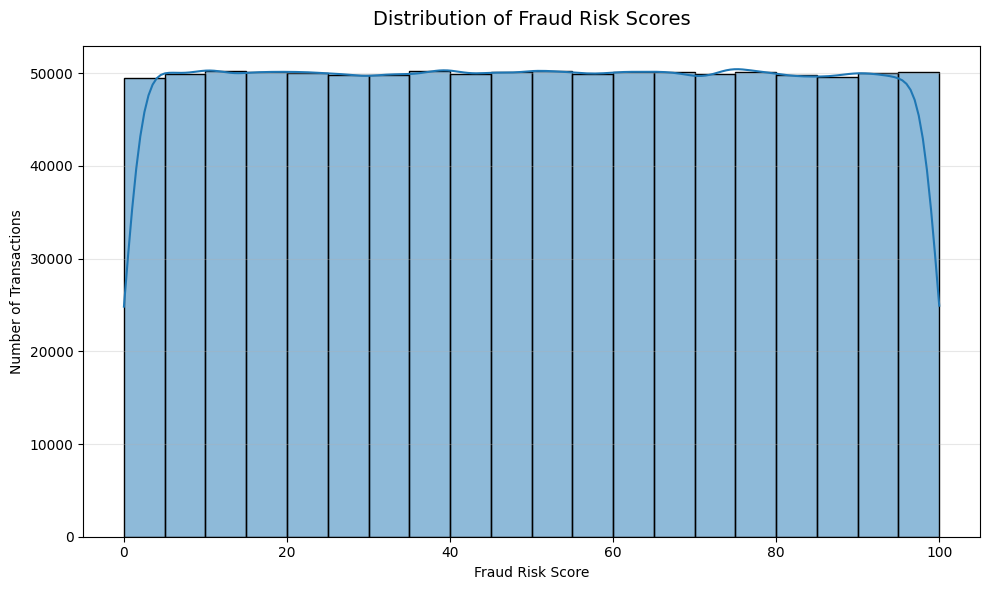

In [73]:
plt.figure(figsize=(10, 6))

sns.histplot(
    data=risk_df,
    x='fraud_risk_score',
    bins=20,
    kde=True
)

plt.title('Distribution of Fraud Risk Scores', fontsize=14, pad=15)
plt.xlabel('Fraud Risk Score')
plt.ylabel('Number of Transactions')
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

#### **Business Insight and Observation**

**3.1 Fraud Risk Score Distribution**  
Lorem Ipsum

#### **Business Insight and Observation**

**3.1 Fraud Risk Score Distribution**  
The fraud risk score is spread from 0 to 100, with an average of approximately 49.96 and a median of 50. The distribution is fairly symmetric across the full range, with no strong concentration in an obviously low-risk or high-risk zone. This suggests that the business should use structured risk levels and targeted controls rather than relying only on the overall average.

### 4.1 Fraud Risk Level Distribution

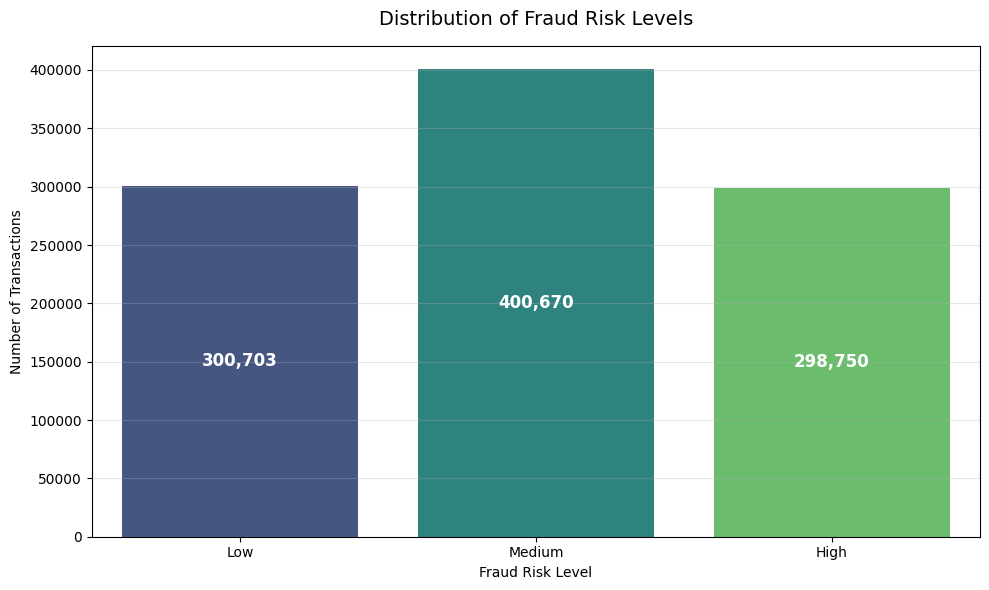

In [74]:
risk_counts = risk_df['fraud_risk_level'].value_counts().reindex(['Low', 'Medium', 'High'], fill_value=0)

plt.figure(figsize=(10, 6))

ax = sns.barplot(
    x=risk_counts.index,
    y=risk_counts.values,
    palette='viridis',
    hue=risk_counts.index,
    legend=False
)

# Add value labels on each marker
for container in ax.containers:
    ax.bar_label(
        container,
        labels=[f'{v:,.0f}' for v in container.datavalues],
        label_type='center',          
        color='white',
        fontsize=12,
        fontweight='bold'
    )

plt.title('Distribution of Fraud Risk Levels', fontsize=14, pad=15)
plt.xlabel('Fraud Risk Level')
plt.ylabel('Number of Transactions')
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

#### **Business Insight and Observation**

**4.1 Fraud Risk Level Distribution**  
Medium-risk transactions form the largest group at 400,670, representing about 40.1% of all orders. Low-risk and high-risk transactions are much more evenly balanced at approximately 30.1% and 29.9%, respectively. Because nearly 70% of orders are not classified as low risk, the company should maintain continuous monitoring and avoid treating fraud prevention as a high-risk-only issue.

## 5. Payment Behavior

### 5.1 Payment Method Distribution

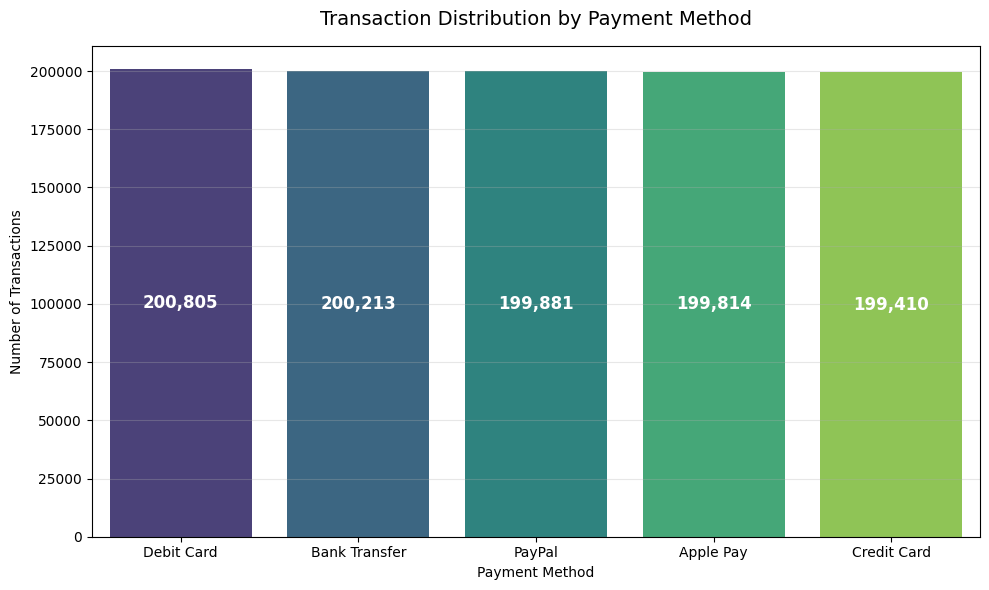

In [75]:
plt.figure(figsize=(10, 6))

ax = sns.barplot(
    x=payment_counts.index,
    y=payment_counts.values,
    palette='viridis',
    hue=payment_counts.index,
    legend=False
)

# Add value labels on each marker
for container in ax.containers:
    ax.bar_label(
        container,
        labels=[f'{v:,.0f}' for v in container.datavalues],
        label_type='center',          
        color='white',
        fontsize=12,
        fontweight='bold'
    )

plt.title('Transaction Distribution by Payment Method', fontsize=14, pad=15)
plt.xlabel('Payment Method')
plt.ylabel('Number of Transactions')
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

#### **Business Insight and Observation**

**5.1 Payment Method Distribution**  
Transaction volume is evenly distributed across all five payment methods, with each method representing roughly 19.9% to 20.1% of orders. Debit Card has the highest count at 200,805, while Credit Card has the lowest at 199,410. This balanced mix means fraud controls should be applied consistently across methods rather than concentrating resources heavily on a single payment channel.

### 5.2 Fraud Risk by Payment Method

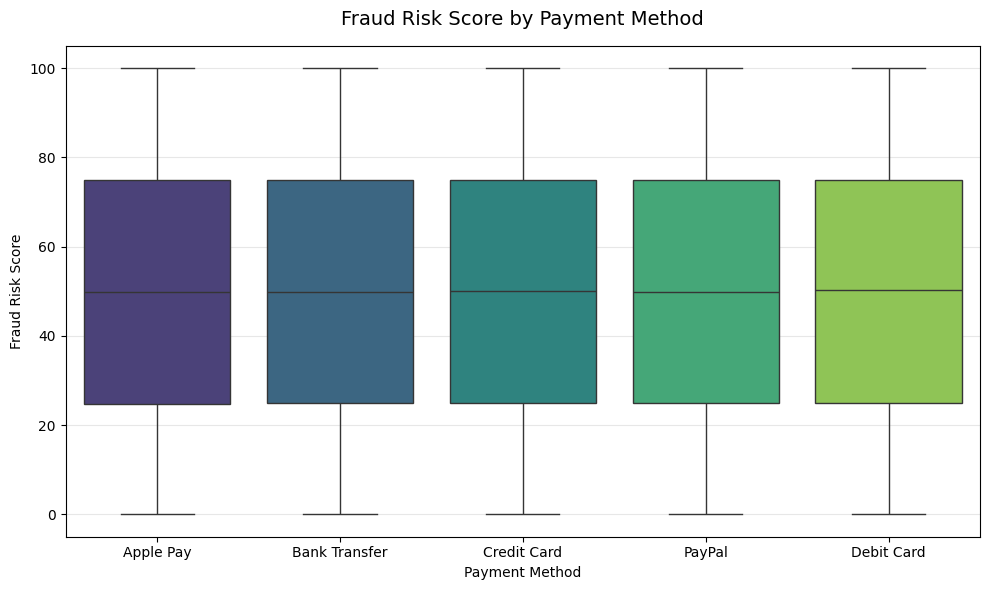

In [76]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=risk_df,
    x='payment_method',
    y='fraud_risk_score',
    palette='viridis',
    hue='payment_method',
    legend=False
)

plt.title('Fraud Risk Score by Payment Method', fontsize=14, pad=15)
plt.xlabel('Payment Method')
plt.ylabel('Fraud Risk Score')
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

#### **Business Insight and Observation**

**5.2 Fraud Risk by Payment Method**  
Average fraud risk is almost identical across payment methods, ranging from approximately 49.87 for Apple Pay to 50.04 for Debit Card. The medians are also tightly grouped near 50, showing no clear payment method with substantially higher risk. Because the distributions overlap closely, payment method alone does not appear to be a strong fraud differentiator and should be used with other behavioral signals.

## 6. Risk vs Order Status

### 6.1 Fraud Risk by Order Status

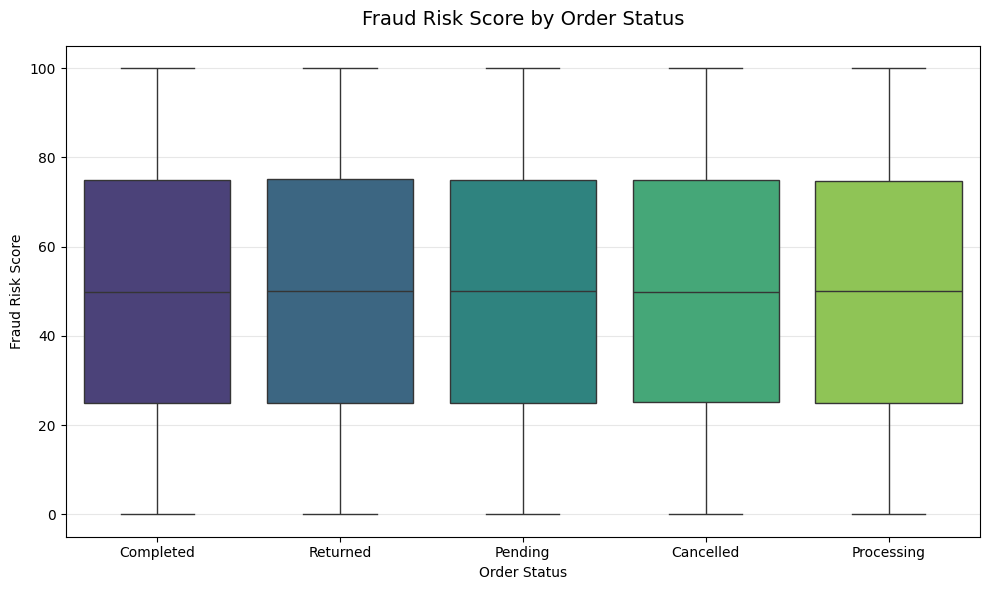

In [77]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=risk_df,
    x='order_status',
    y='fraud_risk_score',
    palette='viridis',
    hue='order_status',
    legend=False
)

plt.title('Fraud Risk Score by Order Status', fontsize=14, pad=15)
plt.xlabel('Order Status')
plt.ylabel('Fraud Risk Score')
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

#### **Business Insight and Observation**

**6.1 Fraud Risk by Order Status**  
Fraud risk remains near 50 for every order status, including Completed, Returned, Cancelled, Pending, and Processing orders. Returned orders have the slightly highest average risk at 50.04, but the gap is too small to identify status as a meaningful standalone predictor. The company should therefore investigate return and cancellation cases for other common factors rather than assuming their status alone signals fraud.

## 7. Risk and Customer Behavior

### 7.1 Fraud Risk vs Abandoned Cart History

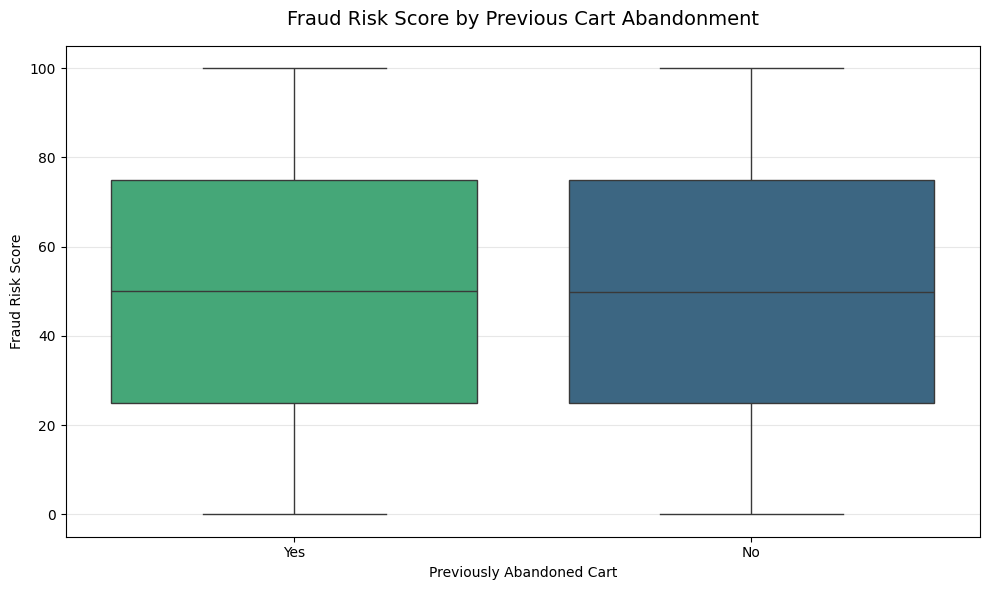

In [78]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=risk_df,
    x='abandoned_cart_before',
    y='fraud_risk_score',
    order=['Yes', 'No'],
    palette='viridis',
    hue='abandoned_cart_before',
    legend=False
)

plt.title('Fraud Risk Score by Previous Cart Abandonment', fontsize=14, pad=15)
plt.xlabel('Previously Abandoned Cart')
plt.ylabel('Fraud Risk Score')
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

#### **Business Insight and Observation**

**7.1 Fraud Risk vs Abandoned Cart History**  
Orders from customers with previous cart abandonment have a slightly higher average risk score of 50.01 compared with 49.92 for those without abandonment history. The difference is minimal and the medians are nearly equal, so cart abandonment does not appear to be a strong fraud signal by itself. It may still be useful as a secondary feature when combined with payment, device, and transaction behavior.

## 8. Risk and Device

### 8.1 Fraud Risk by Device Type

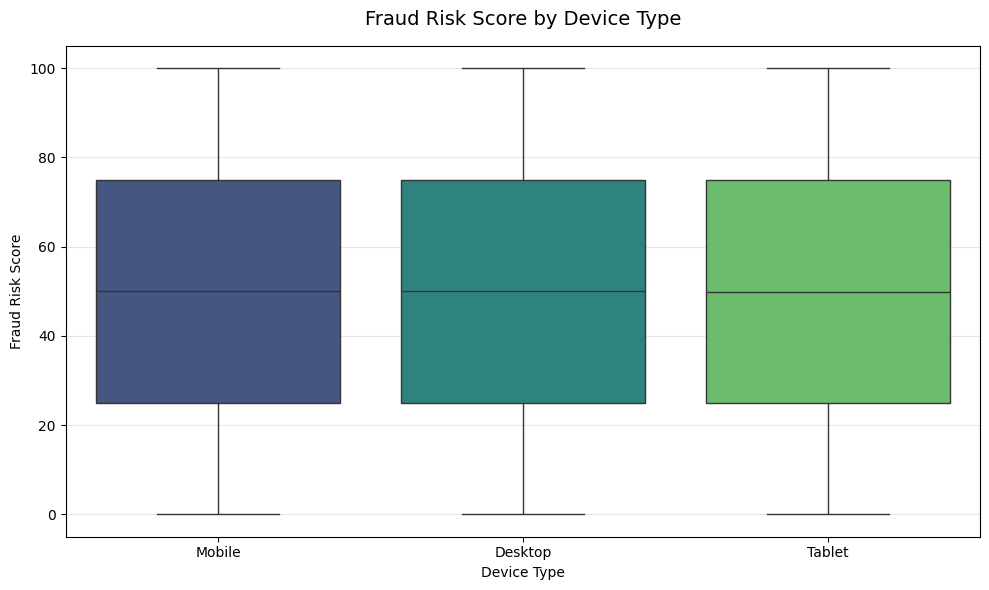

In [79]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=risk_df,
    x='device_type',
    y='fraud_risk_score',
    palette='viridis',
    hue='device_type',
    legend=False
)

plt.title('Fraud Risk Score by Device Type', fontsize=14, pad=15)
plt.xlabel('Device Type')
plt.ylabel('Fraud Risk Score')
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

#### **Business Insight and Observation**

**8.1 Fraud Risk by Device Type**  
Fraud risk scores are nearly the same across Desktop, Mobile, and Tablet, averaging between 49.92 and 50.02. Median scores are also close to 50 for all three devices. This indicates that device type does not create a clear standalone risk separation, and checks should focus on the device's combined behavioral context rather than automatically blocking any one category.

## 9. Financial Impact of Risk

### 9.1 Profit by Fraud Risk Level

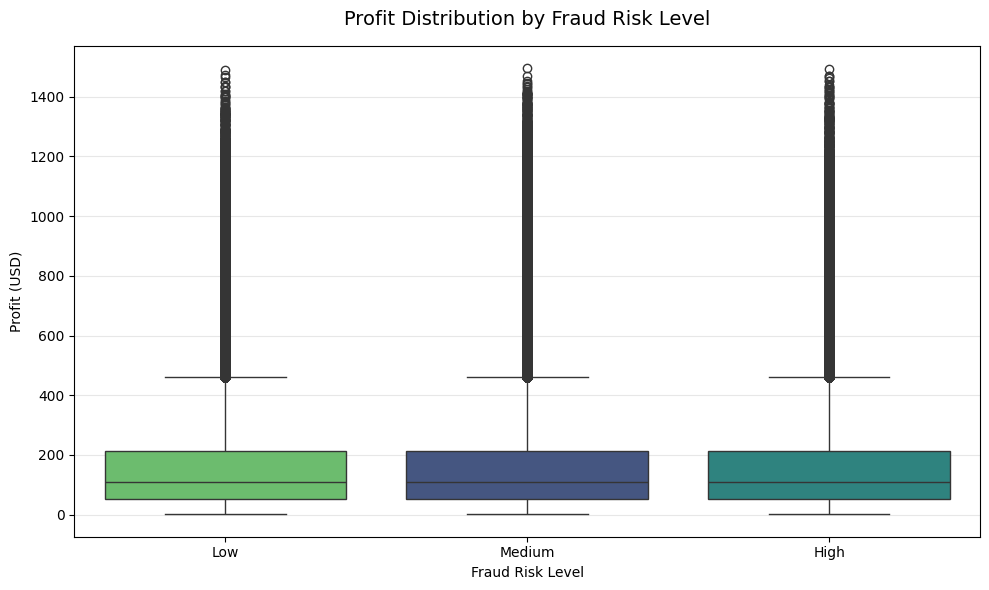

In [80]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=risk_df,
    x='fraud_risk_level',
    y='profit_usd',
    order=['Low', 'Medium', 'High'],
    palette='viridis',
    hue='fraud_risk_level',
    legend=False
)

plt.title('Profit Distribution by Fraud Risk Level', fontsize=14, pad=15)
plt.xlabel('Fraud Risk Level')
plt.ylabel('Profit (USD)')
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

#### **Business Insight and Observation**

**9.1 Profit by Fraud Risk Level**  
Average profit is broadly similar across Low, Medium, and High-risk orders, ranging from approximately $160.69 to $161.28, with medians close to $109. The high-volume Medium-risk group contributes the greatest total profit at about $64.38 million, followed by Low and High-risk groups. This shows that fraud-risk classification is not eliminating profitable transactions, but the overall profit concentration in Medium-risk orders makes that segment important for efficient, balanced monitoring.

> #### **Summary**
> Fraud risk scores are spread evenly across the full 0–100 range, with an average of about 50 and no strong concentration in an obvious low- or high-risk zone. Medium-risk transactions represent the largest group at approximately 40%, while Low and High risk account for about 30% each, meaning fraud monitoring should cover more than only high-risk orders. Payment method, order status, cart abandonment history, and device type show only small differences in average fraud risk, indicating that none of these factors should be used alone to classify an order as fraudulent. Transaction volume is also balanced across payment methods and profit remains similar across risk levels, so overly strict controls could reject legitimate and profitable orders. The company should therefore combine risk scores with payment, device, order, and behavioral signals and apply proportionate actions, such as lightweight checks for Medium-risk orders and deeper verification for High-risk orders.